# Multi-tabel — Ringkasan Berjendela Waktu tanpa Bocor (prediksi churn)
**Kapan dipakai:** tabel anak berisi kejadian bertanggal (belanja, login, klik) dan tebakan
dibuat **pada satu tanggal cutoff**, misalnya "apakah pelanggan ini berhenti membeli setelah
tanggal itu?".

**Idenya:** aturan emas: feature hanya boleh memakai kejadian **sebelum** cutoff, label
dihitung dari kejadian **sesudah** cutoff. Beberapa tanggal cutoff ditumpuk jadi data latih.
Notebook ini juga menunjukkan skor palsu kalau aturan itu dilanggar.

**Langkah:**
1. Ringkas log belanja jadi satu baris per nota.
2. Untuk tiap cutoff: feature dari N hari sebelumnya, label churn dari `HORIZON` hari sesudahnya.
3. Latih di cutoff awal, validasi di cutoff berikutnya, submission untuk cutoff test.

**Data demo:** Online Retail UCI (toko online Inggris, Des 2010 – Des 2011).
Churn = tidak membeli dalam 90 hari setelah cutoff.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/unsupervised"   # GANTI saat lomba
TRANSACTIONS_CSV = f"{DATA_FOLDER}/online_retail.csv"

CUSTOMER_COL = "CustomerID"
INVOICE_COL = "InvoiceNo"
DATE_COL = "InvoiceDate"
HORIZON = 90                     # churn = tidak beli dalam 90 hari setelah cutoff
WINDOWS = [30, 90, 180]          # feature dihitung dari 30, 90, 180 hari sebelum cutoff
TRAIN_CUTOFFS = ["2011-03-01", "2011-04-01", "2011-05-01"]
VALID_CUTOFF = "2011-08-01"      # labelnya (sampai Okt) tidak tumpang-tindih dengan latih
FINAL_TRAIN_CUTOFFS = ["2011-03-01", "2011-04-01", "2011-05-01", "2011-06-01"]
TEST_CUTOFF = "2011-09-01"
SEED = 42

## Langkah 1 — satu baris per nota

In [3]:
retail = pd.read_csv(TRANSACTIONS_CSV, parse_dates=[DATE_COL])
retail = retail.dropna(subset=[CUSTOMER_COL])
retail = retail[retail["Quantity"] > 0]
retail["value"] = retail["Quantity"] * retail["UnitPrice"]

per_invoice = retail.groupby([CUSTOMER_COL, INVOICE_COL])
invoices = pd.DataFrame()
invoices["date"] = per_invoice[DATE_COL].min()
invoices["value"] = per_invoice["value"].sum()
invoices = invoices.reset_index()
customers = sorted(invoices[CUSTOMER_COL].unique())
print(invoices.shape, "|", len(customers), "pelanggan")
invoices.head()

(6908, 4) | 1489 pelanggan


,CustomerID,InvoiceNo,date,value
0,12347,537626,2010-12-07 14:57:00,711.79
1,12347,542237,2011-01-26 14:30:00,475.39
2,12347,549222,2011-04-07 10:43:00,636.25
3,12347,556201,2011-06-09 13:01:00,382.52
4,12347,562032,2011-08-02 08:48:00,584.91


## Langkah 2a — feature relatif terhadap cutoff
`days_before` = jarak tiap nota ke cutoff. Versi benar: fungsi diberi nota `< cutoff` saja.

In [4]:
def make_features(events, cutoff):
    days_before = (cutoff - events["date"]).dt.days
    table = pd.DataFrame()
    table["customer"] = customers
    table["cutoff"] = cutoff
    for width in WINDOWS:
        inside = events[days_before <= width]
        counts = inside.groupby(CUSTOMER_COL).size()
        spending = inside.groupby(CUSTOMER_COL)["value"].sum()
        table[f"invoices_{width}d"] = table["customer"].map(counts).fillna(0)
        table[f"spending_{width}d"] = table["customer"].map(spending).fillna(0)
    last_date = events.groupby(CUSTOMER_COL)["date"].max()
    gap = cutoff - table["customer"].map(last_date)
    table["days_since_last"] = gap.dt.days
    return table


# coba pada cutoff latih pertama
first_cutoff = pd.Timestamp(TRAIN_CUTOFFS[0])
print(make_features(invoices[invoices["date"] < first_cutoff], first_cutoff).head())

   customer     cutoff  invoices_30d  spending_30d  invoices_90d  \
0     12347 2011-03-01           0.0           0.0           2.0   
1     12350 2011-03-01           1.0         334.4           1.0   
2     12358 2011-03-01           0.0           0.0           0.0   
3     12370 2011-03-01           0.0           0.0           2.0   
4     12374 2011-03-01           0.0           0.0           0.0   

   spending_90d  invoices_180d  spending_180d  days_since_last  
0       1187.18            2.0        1187.18             33.0  
1        334.40            1.0         334.40             26.0  
2          0.00            0.0           0.00              NaN  
3       1868.02            2.0        1868.02             73.0  
4          0.00            0.0           0.00              NaN  


## Langkah 2b — tabel pelanggan x cutoff, versi benar dan versi bocor
Versi bocor = feature dihitung dari SEMUA nota, termasuk masa depan (sengaja salah).
Populasi = pelanggan yang aktif 90 hari sebelum cutoff.

In [5]:
all_cutoffs = sorted(set(FINAL_TRAIN_CUTOFFS + [VALID_CUTOFF, TEST_CUTOFF]))
honest_parts = []
leaky_parts = []
for date in all_cutoffs:
    cutoff = pd.Timestamp(date)
    honest = make_features(invoices[invoices["date"] < cutoff], cutoff)
    leaky = make_features(invoices, cutoff)
    horizon_end = cutoff + pd.DateOffset(days=HORIZON)
    future = invoices[(invoices["date"] >= cutoff) & (invoices["date"] < horizon_end)]
    honest["churn"] = (~honest["customer"].isin(future[CUSTOMER_COL])).astype(int)
    leaky["churn"] = honest["churn"]
    is_active = honest["invoices_90d"] > 0
    honest_parts.append(honest[is_active])
    leaky_parts.append(leaky[is_active])
    churn_share = honest["churn"][is_active].mean()
    print(date, "| aktif:", is_active.sum(), "| churn:", round(churn_share, 3))

honest_data = pd.concat(honest_parts)
leaky_data = pd.concat(leaky_parts)
FEATURE_COLS = list(honest_data.columns.drop(["customer", "cutoff", "churn"]))
print(FEATURE_COLS)

2011-03-01 | aktif: 613 | churn: 0.427
2011-04-01 | aktif: 633 | churn: 0.409
2011-05-01 | aktif: 687 | churn: 0.397
2011-06-01 | aktif: 701 | churn: 0.429
2011-08-01 | aktif: 698 | churn: 0.365
2011-09-01 | aktif: 666 | churn: 0.314
['invoices_30d', 'spending_30d', 'invoices_90d', 'spending_90d', 'invoices_180d', 'spending_180d', 'days_since_last']


## Langkah 3a — validasi menurut waktu: benar vs bocor

AUC feature benar                     : 0.7309
AUC feature bocor (tampak hebat, palsu): 0.9834
AUC model bocor di kondisi nyata       : 0.6745


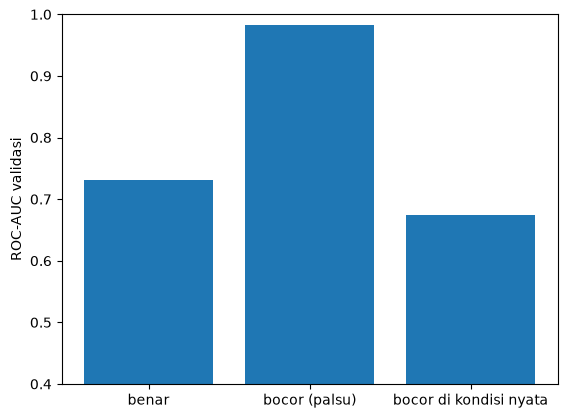

In [6]:
is_train = honest_data["cutoff"].isin(pd.to_datetime(TRAIN_CUTOFFS))
is_valid = honest_data["cutoff"] == pd.Timestamp(VALID_CUTOFF)

model = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=8, random_state=SEED,
                       verbose=-1)

model.fit(honest_data[FEATURE_COLS][is_train], honest_data["churn"][is_train])
honest_scores = model.predict_proba(honest_data[FEATURE_COLS][is_valid])[:, 1]
honest_auc = roc_auc_score(honest_data["churn"][is_valid], honest_scores)

model.fit(leaky_data[FEATURE_COLS][is_train], leaky_data["churn"][is_train])
leaky_scores = model.predict_proba(leaky_data[FEATURE_COLS][is_valid])[:, 1]
leaky_auc = roc_auc_score(leaky_data["churn"][is_valid], leaky_scores)
real_scores = model.predict_proba(honest_data[FEATURE_COLS][is_valid])[:, 1]
real_auc = roc_auc_score(honest_data["churn"][is_valid], real_scores)

print("AUC feature benar                     :", round(honest_auc, 4))
print("AUC feature bocor (tampak hebat, palsu):", round(leaky_auc, 4))
print("AUC model bocor di kondisi nyata       :", round(real_auc, 4))
plt.bar(["benar", "bocor (palsu)", "bocor di kondisi nyata"], [honest_auc, leaky_auc, real_auc])
plt.ylabel("ROC-AUC validasi")
plt.ylim(0.4, 1)
plt.show()

## Latih ulang (versi benar, cutoff Mar–Jun) + submission untuk cutoff test

In [7]:
is_final_train = honest_data["cutoff"].isin(pd.to_datetime(FINAL_TRAIN_CUTOFFS))
is_test = honest_data["cutoff"] == pd.Timestamp(TEST_CUTOFF)
train = honest_data[is_final_train]
test = honest_data[is_test]

model.fit(train[FEATURE_COLS], train["churn"])
probabilities = model.predict_proba(test[FEATURE_COLS])
predictions = probabilities[:, 1]          # peluang churn

submission = pd.DataFrame()
submission["CustomerID"] = test["customer"]
submission["churn"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,CustomerID,churn
0,12347,0.131789
2,12358,0.533758
7,12378,0.576171
10,12395,0.126514
11,12397,0.259036


## Cek dengan kunci jawaban (HAPUS saat lomba)
Di data demo label churn cutoff test bisa dihitung karena datanya sampai Des 2011.

In [8]:
print("ROC-AUC test:", round(roc_auc_score(test["churn"], predictions), 4))

ROC-AUC test: 0.723
